# ECE 285 Homework 2: WikiArt Painting Generation with GAN

本 Notebook 实现了一个针对 **WikiArt (81,444 张多流派艺术画作)** 数据集与 **NVIDIA GeForce RTX 5070 Ti (15.89 GB VRAM, CUDA 13.0)** 深度优化的生成对抗网络训练与评估全流程，严格覆盖作业报告所需的全部实验输出：

1. **超参数设置 (Hyperparameter Settings)**：集中管理并导出标准化配置表。
2. **模型实现 (SNGAN-ResNet with Self-Attention)**：
   - 生成器采用 `Nearest Upsample + Conv3x3` 残差上采样块（消除转置卷积棋盘格伪影）+ `BatchNorm2d` + `SiLU`，并在 $32\times 32$ 尺度引入 `SDPA Self-Attention` 增强画面全局构图。
   - 判别器采用全程 `Spectral Normalization` 残差下采样块 + $32\times 32$ `Self-Attention` + 全局求和池化（无 BatchNorm，保证对抗判别稳定性）。
   - 结合 **Hinge Loss**、**TTUR** 双时间尺度学习率、**EMA (指数移动平均)** 生成器权重以及轻度对称 **DiffAugment**，防止在高多样性 WikiArt 数据集上发生模式崩塌或判别器过拟合。
3. **显存与耗时优化 (RTX 5070 Ti / `ml-pip`)**：
   - **一次性多线程预处理与 Memmap 缓存**：原图平均分辨率高达 `1382×1492`（最高 `15754×17768`），若每个 Epoch 实时解码 81,444 张原图将严重卡死在 CPU I/O 上。本流程采用 16 线程流式预处理并保存为连续 `uint8 numpy.memmap`（`128×128` 约 `3.73 GB` 磁盘，训练期内存占用极低），彻底避开 Windows 下 `DataLoader` 多进程 `spawn` 阻塞。
   - **BF16 混合精度 & 图复用**：启用 `torch.amp.autocast('cuda', dtype=torch.bfloat16)`、`channels_last` 内存排布，并在更新生成器时直接复用判别器阶段生成的 `fake` 计算图，在 RTX 5070 Ti 上峰值显存控制在 **~5.5 GB**（总显存 15.89 GB）。
4. **评估指标 (FID & Inception Score)**：
   - 对齐 [PyTorch-Ignite GAN Evaluation 博客](https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/)（`Inception-v3` + `299×299` Bilinear 抗锯齿插值），修复原博客未将 `Tanh [-1, 1]` 映射至 `[0, 1]` 及缺失 ImageNet 标准化的问题，预缓存真实 WikiArt 统计量并采用 GPU 批量插值提速。
   - 默认提供零额外依赖的 `ml-pip` 兼容实现（`torchvision` + `scipy`），同时保留可选的原生 `pytorch-ignite` Engine 评估分支。
5. **报告素材导出**：自动生成高清 Loss 曲线、FID/IS 演化曲线、真假对比图、生成画廊与潜空间球面插值图（保存在 `./outputs/figures/`）。

In [1]:
import os
import sys
import json
import time
import math
import copy
import random
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import scipy.linalg
from PIL import Image, ImageOps
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import spectral_norm
from torchvision.models import inception_v3, Inception_V3_Weights
import torchvision.utils as vutils

%matplotlib inline

# 允许加载超大画幅图像，避免 PIL DecompressionBomb 报错或警告
Image.MAX_IMAGE_PIXELS = None

# ==========================================
# 1. 运行环境与 CUDA 硬件检查
# ==========================================
print(f"Python Executable : {sys.executable}")
if "ml-pip" not in sys.executable.lower():
    print("[Warning] 当前内核似乎不是 conda 环境 'ml-pip'，请确认 Jupyter Kernel 选择正确。")

print(f"PyTorch Version   : {torch.__version__}")
print(f"CUDA Available    : {torch.cuda.is_available()}")
assert torch.cuda.is_available(), "未检测到 CUDA 设备，请检查 ml-pip 环境与 GPU 驱动！"

DEVICE = torch.device("cuda:0")
gpu_name = torch.cuda.get_device_name(DEVICE)
gpu_vram_gb = torch.cuda.get_device_properties(DEVICE).total_memory / (1024 ** 3)
print(f"GPU Device        : {gpu_name} ({gpu_vram_gb:.2f} GB VRAM)")

# 针对 RTX 5070 Ti (Blackwell) 启用高效算子搜索与 TF32 矩阵乘
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

# ==========================================
# 2. 全局超参数配置 (CONFIG)
# ==========================================
CONFIG = {
    # 路径配置
    "data_dir": "./data",
    "cache_dir": "./cache",
    "output_dir": "./outputs",

    # 数据与分辨率（128x128 兼顾画质与显存/耗时；若追求更快基准测试可改为 64）
    "image_size": 128,              # 支持 128 或 64
    "num_preprocess_workers": min(16, os.cpu_count() or 8),

    # 模型超参数 (Self-Attention SNGAN-ResNet)
    "z_dim": 128,
    "use_self_attention": True,     # 在 32x32 尺度嵌入 SDPA Self-Attention
    "g_channels_128": [384, 384, 256, 128, 64, 32],   # 4 -> 8 -> 16 -> 32 -> 64 -> 128
    "d_channels_128": [3, 32, 64, 128, 256, 384],     # 128 -> 64 -> 32 -> 16 -> 8 -> 4
    "g_channels_64":  [512, 256, 128, 64, 32],        # 4 -> 8 -> 16 -> 32 -> 64
    "d_channels_64":  [3, 64, 128, 256, 512],         # 64 -> 32 -> 16 -> 8 -> 4

    # 训练超参数 (RTX 5070 Ti: 128x128 BS=128 Peak VRAM ~5.4 GB, ~100s/epoch)
    "batch_size": 128,
    "epochs": 25,                   # 25 epochs (~15,900 steps, 预计 ~42 分钟); 可按需调整为 15~30
    "lr_G": 1e-4,                   # TTUR: 判别器学习率略高于生成器
    "lr_D": 2e-4,
    "betas": (0.0, 0.999),          # SNGAN / BigGAN 标准 Adam beta1=0.0
    "ema_decay": 0.999,
    "use_amp": True,
    "amp_dtype": "bfloat16",        # Blackwell 原生 BF16，动态范围与 FP32 一致且无需 GradScaler
    "use_diffaug": True,
    "diffaug_policy": "color,translation",

    # 评估与保存设置
    "seed": 42,
    "eval_every": 5,                # Epoch 1 及每 eval_every 个 epoch 评估 FID & IS
    "eval_num_samples": 5000,       # 训练中间评估样本数 (~3-4s 完成)
    "final_eval_num_samples": 10000,# 最终报告高精度评估样本数
    "eval_batch_size": 64,          # 299x299 Inception 推理批大小，显存占用 < 1 GB
    "eval_backend": "auto",         # 'auto' (自动探测 ignite，无则用等价 PyTorch+SciPy) | 'pytorch' | 'ignite'
    "num_sample_images": 64,        # 可视化网格图 (8x8)
    "resume": True,                 # 支持从 last_checkpoint.pt 断点续训
}

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(CONFIG["seed"])

# 创建输出目录
for sub in ["", "checkpoints", "samples", "figures"]:
    Path(CONFIG["output_dir"], sub).mkdir(parents=True, exist_ok=True)
Path(CONFIG["cache_dir"]).mkdir(parents=True, exist_ok=True)

# 导出并打印超参数汇总表（方便直接填入 2 页 NeurIPS 报告）
with open(Path(CONFIG["output_dir"], "config.json"), "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)

hp_rows = [(k, str(v)) for k, v in CONFIG.items() if not k.startswith("g_channels") and not k.startswith("d_channels")]
hp_df = pd.DataFrame(hp_rows, columns=["Hyperparameter", "Value"])
print("\n=== Hyperparameter Summary ===")
print(hp_df.to_string(index=False))


Python Executable : d:\Anaconda\envs\ml-pip\python.exe
PyTorch Version   : 2.10.0+cu130
CUDA Available    : True
GPU Device        : NVIDIA GeForce RTX 5070 Ti (15.89 GB VRAM)

=== Hyperparameter Summary ===
        Hyperparameter             Value
              data_dir            ./data
             cache_dir           ./cache
            output_dir         ./outputs
            image_size               128
num_preprocess_workers                16
                 z_dim               128
    use_self_attention              True
            batch_size               128
                epochs                25
                  lr_G            0.0001
                  lr_D            0.0002
                 betas      (0.0, 0.999)
             ema_decay             0.999
               use_amp              True
             amp_dtype          bfloat16
           use_diffaug              True
        diffaug_policy color,translation
                  seed                42
            e

## 1. WikiArt 数据集探索 (EDA)

检查 `./data` 下 27 个艺术流派目录的图片数量分布及 `classes.csv` 的原始分辨率特征。

艺术流派类别数: 27
有效绘画图像总数: 81,444
classes.csv 元数据记录数: 80,042
原图宽度分布 (px): min=1381, median=1382, max=15754
原图高度分布 (px): min=1381, median=1492, max=17768


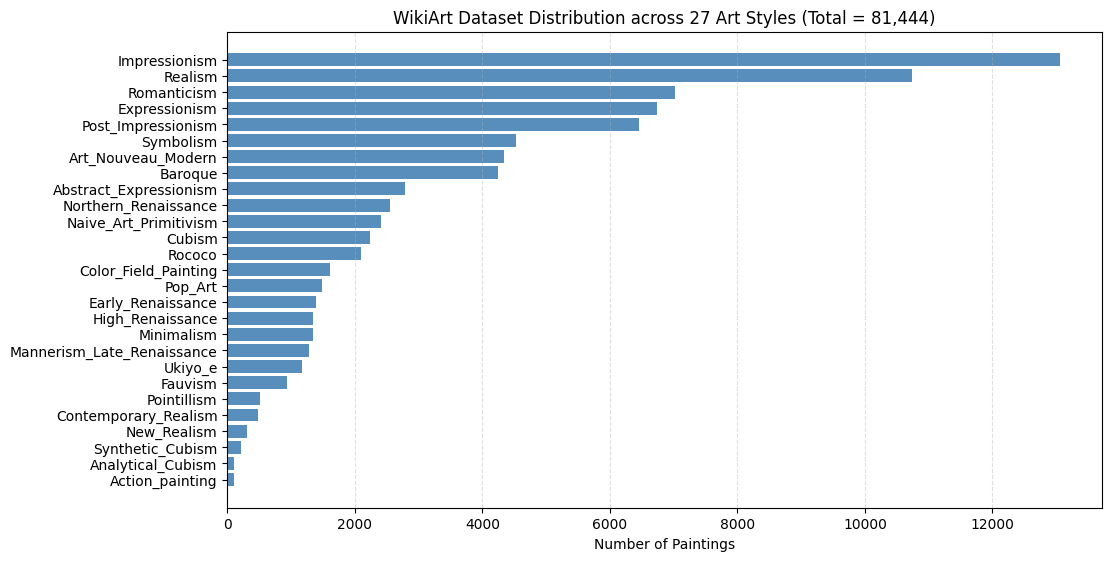

In [2]:
data_root = Path(CONFIG["data_dir"])
assert data_root.exists(), f"数据集目录不存在: {data_root.resolve()}"

style_dirs = sorted([d for d in data_root.iterdir() if d.is_dir()])
class_names = [d.name for d in style_dirs]

style_counts = {}
all_image_records = []
valid_exts = {".jpg", ".jpeg", ".png"}

for class_idx, d in enumerate(style_dirs):
    files = sorted([p for p in d.iterdir() if p.is_file() and p.suffix.lower() in valid_exts])
    style_counts[d.name] = len(files)
    for p in files:
        all_image_records.append((str(p), class_idx))

print(f"艺术流派类别数: {len(class_names)}")
print(f"有效绘画图像总数: {len(all_image_records):,}")

classes_csv = data_root / "classes.csv"
if classes_csv.exists():
    meta_csv = pd.read_csv(classes_csv)
    print(f"classes.csv 元数据记录数: {len(meta_csv):,}")
    print(
        f"原图宽度分布 (px): min={meta_csv['width'].min()}, "
        f"median={meta_csv['width'].median():.0f}, max={meta_csv['width'].max()}"
    )
    print(
        f"原图高度分布 (px): min={meta_csv['height'].min()}, "
        f"median={meta_csv['height'].median():.0f}, max={meta_csv['height'].max()}"
    )

# 绘制流派分布图
sorted_items = sorted(style_counts.items(), key=lambda kv: kv[1], reverse=True)
names, counts = zip(*sorted_items)

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
ax.barh(names[::-1], counts[::-1], color="steelblue", alpha=0.9)
ax.set_title(f"WikiArt Dataset Distribution across {len(class_names)} Art Styles (Total = {len(all_image_records):,})")
ax.set_xlabel("Number of Paintings")
ax.grid(axis="x", linestyle="--", alpha=0.4)
fig.savefig(Path(CONFIG["output_dir"], "figures", "wikiart_style_distribution.png"), dpi=200)
plt.show()


## 2. 高效图像预处理与 Memmap 缓存构建

由于原图分辨率极高（中位数 `1382×1492`），若在训练循环中逐 epoch 解码 81,444 张原图会产生巨大的 CPU 解码瓶颈。本节执行：

1. **保持比例缩放 + 中心裁剪**：与 `2021-08-11-GAN-evaluation-using-FID-and-IS.ipynb` 一致，先将短边按双线性插值缩放到 `image_size`，再 `CenterCrop(image_size)`，避免画作被压扁。
2. **流式写入 `numpy.memmap`**：使用 16 线程并行解码并直接写入磁盘映射文件（`128×128` 约 `3.73 GB`，`64×64` 约 `0.93 GB`），内存占用全程控制在 `< 300 MB`；首次构建后永久复用。
3. **全局均匀抽样真实评估集**：参考博客中使用 `range(3000)` 直接截断会导致所有真实样本集中在前两个字母目录（如 `Abstract_Expressionism` 占 2,782 张）。这里采用**固定种子全局随机均匀抽样 10,000 张**覆盖全部 27 个流派，确保 FID 评估无偏。

[Cache Build] 正在将 81,444 张图像预处理为 128x128 RGB memmap (workers=16)...


Preprocessing: 100%|██████████| 81444/81444 [06:03<00:00, 224.34it/s]


[Cache Done] 有效图像=81,444, 文件大小=3.73 GB, 耗时=364.6s
Train steps per epoch: 636 (batch_size=128)


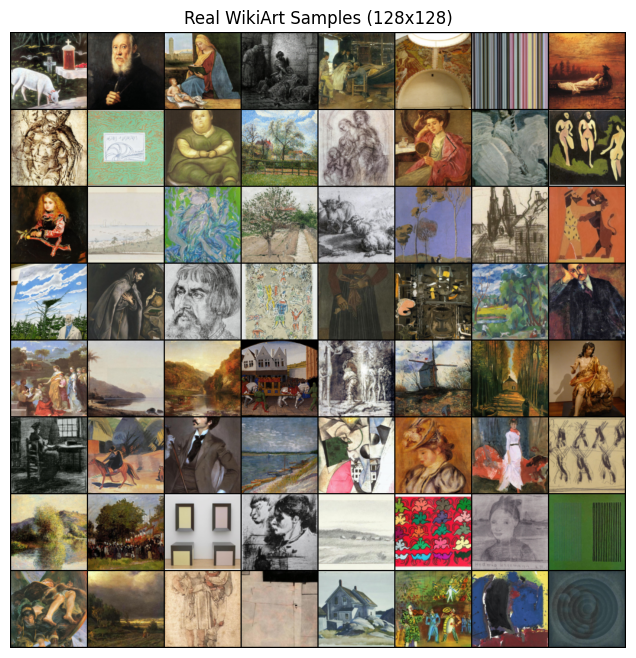

In [3]:
IMG_SIZE = CONFIG["image_size"]
MEMMAP_PATH = Path(CONFIG["cache_dir"], f"wikiart_{IMG_SIZE}x{IMG_SIZE}_rgb.npy")
META_PATH = Path(CONFIG["cache_dir"], f"wikiart_{IMG_SIZE}x{IMG_SIZE}_meta.json")

def resize_and_center_crop(img: Image.Image, target_size: int) -> np.ndarray:
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    if w == 0 or h == 0:
        raise ValueError("Empty image dimensions")
    # 等比缩放使短边等于 target_size（等效 torchvision.transforms.Resize(target_size)）
    if w < h:
        new_w = target_size
        new_h = max(target_size, int(round(h * target_size / w)))
    else:
        new_h = target_size
        new_w = max(target_size, int(round(w * target_size / h)))
    if (w, h) != (new_w, new_h):
        img = img.resize((new_w, new_h), Image.Resampling.BILINEAR)
    left = (new_w - target_size) // 2
    top = (new_h - target_size) // 2
    img = img.crop((left, top, left + target_size, top + target_size))
    return np.asarray(img, dtype=np.uint8)

def _process_one(args):
    idx, path_str, label, target_size = args
    try:
        with Image.open(path_str) as im:
            arr = resize_and_center_crop(im, target_size)
        return idx, arr, label, None
    except Exception as e:
        return idx, None, label, f"{path_str}: {e}"

def build_or_load_cache(records, class_names, img_size, memmap_path, meta_path, num_workers, eval_pool_size, seed):
    if memmap_path.exists() and meta_path.exists():
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
        if meta.get("image_size") == img_size and meta.get("complete", False):
            arr = np.load(memmap_path, mmap_mode="r")
            print(f"[Cache Hit] 已加载预处理缓存: {memmap_path} | shape={arr.shape}, dtype={arr.dtype}")
            return arr, meta

    n_total = len(records)
    tmp_path = memmap_path.with_suffix(".tmp.npy")
    if tmp_path.exists():
        tmp_path.unlink()

    print(f"[Cache Build] 正在将 {n_total:,} 张图像预处理为 {img_size}x{img_size} RGB memmap (workers={num_workers})...")
    t0 = time.time()
    mm = np.lib.format.open_memmap(tmp_path, mode="w+", dtype=np.uint8, shape=(n_total, img_size, img_size, 3))

    tasks = [(i, p, lbl, img_size) for i, (p, lbl) in enumerate(records)]
    valid_count = 0
    labels_list = []
    errors = []

    with ThreadPoolExecutor(max_workers=num_workers) as pool:
        for _, arr, lbl, err in tqdm(pool.map(_process_one, tasks, chunksize=32), total=n_total, desc="Preprocessing"):
            if err is not None or arr is None:
                errors.append(err)
                continue
            mm[valid_count] = arr
            labels_list.append(int(lbl))
            valid_count += 1
            if valid_count % 4000 == 0:
                mm.flush()
    mm.flush()
    del mm

    if errors:
        print(f"[Warning] 跳过 {len(errors)} 张损坏图像，示例: {errors[:3]}")

    # 若存在损坏图像则裁剪到精确有效行数；否则直接原子重命名
    if valid_count == n_total:
        tmp_path.replace(memmap_path)
    else:
        src_mm = np.load(tmp_path, mmap_mode="r")
        dst_mm = np.lib.format.open_memmap(memmap_path, mode="w+", dtype=np.uint8, shape=(valid_count, img_size, img_size, 3))
        for start in range(0, valid_count, 4096):
            end = min(start + 4096, valid_count)
            dst_mm[start:end] = src_mm[start:end]
        dst_mm.flush()
        del src_mm, dst_mm
        tmp_path.unlink()

    rng = np.random.default_rng(seed)
    eval_pool_n = min(eval_pool_size, valid_count)
    eval_indices = rng.choice(valid_count, size=eval_pool_n, replace=False).tolist()

    meta = {
        "complete": True,
        "image_size": img_size,
        "num_images": valid_count,
        "class_names": class_names,
        "labels": labels_list,
        "eval_indices": eval_indices,
    }
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f)

    elapsed = time.time() - t0
    size_gb = memmap_path.stat().st_size / (1024 ** 3)
    print(f"[Cache Done] 有效图像={valid_count:,}, 文件大小={size_gb:.2f} GB, 耗时={elapsed:.1f}s")
    return np.load(memmap_path, mmap_mode="r"), meta

images_mm, dataset_meta = build_or_load_cache(
    records=all_image_records,
    class_names=class_names,
    img_size=IMG_SIZE,
    memmap_path=MEMMAP_PATH,
    meta_path=META_PATH,
    num_workers=CONFIG["num_preprocess_workers"],
    eval_pool_size=CONFIG["final_eval_num_samples"],
    seed=CONFIG["seed"],
)

class MemmapBatchLoader:
    """零多进程开销的 Memmap 批量数据加载器：直接在 GPU 上做 float32 归一化与随机水平翻转"""
    def __init__(self, memmap_arr, batch_size, device, shuffle=True, drop_last=True, random_flip=True, indices=None):
        self.arr = memmap_arr
        self.batch_size = batch_size
        self.device = device
        self.shuffle = shuffle
        self.drop_last = drop_last
        self.random_flip = random_flip
        self.base_indices = np.arange(len(memmap_arr)) if indices is None else np.asarray(indices, dtype=np.int64)

    def __len__(self):
        n = len(self.base_indices)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        order = self.base_indices.copy()
        if self.shuffle:
            np.random.shuffle(order)
        n = len(order)
        limit = (n // self.batch_size) * self.batch_size if self.drop_last else n
        for start in range(0, limit, self.batch_size):
            batch_idx = order[start:start + self.batch_size]
            batch_np = np.ascontiguousarray(self.arr[batch_idx])  # (B, H, W, 3) uint8
            x = torch.from_numpy(batch_np).to(self.device, non_blocking=True)
            x = x.permute(0, 3, 1, 2).float().mul_(1.0 / 127.5).sub_(1.0)  # [-1, 1]
            if self.random_flip:
                flip_mask = torch.rand(x.size(0), 1, 1, 1, device=self.device) < 0.5
                x = torch.where(flip_mask, x.flip(-1), x)
            yield x.contiguous(memory_format=torch.channels_last)

train_loader = MemmapBatchLoader(
    images_mm,
    batch_size=CONFIG["batch_size"],
    device=DEVICE,
    shuffle=True,
    drop_last=True,
    random_flip=True,
)
print(f"Train steps per epoch: {len(train_loader)} (batch_size={CONFIG['batch_size']})")

# 预览 64 张真实 WikiArt 样本
preview_idx = dataset_meta["eval_indices"][:CONFIG["num_sample_images"]]
preview_imgs = torch.from_numpy(np.ascontiguousarray(images_mm[preview_idx])).permute(0, 3, 1, 2).float() / 255.0
preview_grid = vutils.make_grid(preview_imgs, nrow=8, padding=2)
fig, ax = plt.subplots(figsize=(8, 8))
ax.axis("off")
ax.set_title(f"Real WikiArt Samples ({IMG_SIZE}x{IMG_SIZE})")
ax.imshow(preview_grid.permute(1, 2, 0).numpy())
fig.savefig(Path(CONFIG["output_dir"], "figures", "real_samples_preview.png"), dpi=250, bbox_inches="tight")
plt.show()


## 3. GAN 模型实现：`Self-Attention SNGAN-ResNet`

- **Generator ($G$)**：
  - 将 $z \sim \mathcal{N}(0, I_{128})$ 线性映射为 $4\times 4$ 特征图；
  - 通过多级 `ResBlockUp`（`BatchNorm2d` + `SiLU` + `Nearest Upsample` + `Conv3x3`）上采样至目标分辨率（$64\times 64$ 或 $128\times 128$），彻底避免 `ConvTranspose2d` 的棋盘格伪影；
  - 在 $32\times 32$ 空间分辨率嵌入基于 PyTorch `F.scaled_dot_product_attention` 的 `SelfAttention` 层（带初始化为 0 的残差系数 $\gamma$）。
- **Discriminator ($D$)**：
  - 全部卷积与线性层应用 **Spectral Normalization (`spectral_norm`)** 严格约束 Lipschitz 常数，不用 BatchNorm；
  - 第一个 `ResBlockDown` 不在输入端加激活函数以保留 `[-1, 0]` 暗部信息；
  - 末端使用全局求和池化（Global Sum Pooling）+ `SN-Linear` 输出未经 Sigmoid 的判别分数。
- **EMA 平滑权重**：维护 `netG_ema`（`decay=0.999`，含参数与 `BatchNorm` buffers 同步），用于评估与最终绘画生成。

In [7]:
class SelfAttention(nn.Module):
    """基于 scaled_dot_product_attention 的高效自注意力模块 (SAGAN 风格)"""
    def __init__(self, channels: int, use_sn: bool = True):
        super().__init__()
        self.ch_qk = max(channels // 8, 16)
        self.ch_v = channels // 2
        qkv_conv = nn.Conv2d(channels, self.ch_qk * 2 + self.ch_v, kernel_size=1, bias=False)
        out_conv = nn.Conv2d(self.ch_v, channels, kernel_size=1, bias=False)
        self.qkv = spectral_norm(qkv_conv) if use_sn else qkv_conv
        self.out = spectral_norm(out_conv) if use_sn else out_conv
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, _, h, w = x.shape
        q, k, v = torch.split(self.qkv(x), [self.ch_qk, self.ch_qk, self.ch_v], dim=1)
        q = q.flatten(2).transpose(1, 2).unsqueeze(1)  # (B, 1, HW, C_qk)
        k = k.flatten(2).transpose(1, 2).unsqueeze(1)
        v = v.flatten(2).transpose(1, 2).unsqueeze(1)
        attn = F.scaled_dot_product_attention(q, k, v)
        attn = attn.squeeze(1).transpose(1, 2).reshape(b, self.ch_v, h, w)
        return x + self.gamma * self.out(attn)


class ResBlockUp(nn.Module):
    def __init__(self, in_c: int, out_c: int):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_c)
        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, stride=1, padding=1, bias=False)
        self.skip = nn.Conv2d(in_c, out_c, kernel_size=1, stride=1, padding=0, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.interpolate(F.silu(self.bn1(x)), scale_factor=2, mode="nearest")
        h = self.conv1(h)
        h = self.conv2(F.silu(self.bn2(h)))
        s = self.skip(F.interpolate(x, scale_factor=2, mode="nearest"))
        return h + s


class ResBlockDown(nn.Module):
    def __init__(self, in_c: int, out_c: int, first: bool = False):
        super().__init__()
        self.first = first
        self.conv1 = spectral_norm(nn.Conv2d(in_c, out_c, kernel_size=3, stride=1, padding=1))
        self.conv2 = spectral_norm(nn.Conv2d(out_c, out_c, kernel_size=3, stride=1, padding=1))
        self.skip = spectral_norm(nn.Conv2d(in_c, out_c, kernel_size=1, stride=1, padding=0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = x if self.first else F.leaky_relu(x, 0.2, inplace=False)
        h = self.conv1(h)
        h = F.leaky_relu(h, 0.2, inplace=False)
        h = F.avg_pool2d(self.conv2(h), kernel_size=2)
        s = self.skip(F.avg_pool2d(x, kernel_size=2))
        return h + s


class Generator(nn.Module):
    def __init__(self, z_dim: int = 128, image_size: int = 128, use_attention: bool = True):
        super().__init__()
        assert image_size in (64, 128), f"仅支持 64 或 128 分辨率，当前为 {image_size}"
        ch = CONFIG["g_channels_128"] if image_size == 128 else CONFIG["g_channels_64"]
        self.c0 = ch[0]
        self.fc = nn.Linear(z_dim, self.c0 * 4 * 4)

        layers = []
        cur_res = 4
        for i in range(len(ch) - 1):
            layers.append(ResBlockUp(ch[i], ch[i + 1]))
            cur_res *= 2
            if use_attention and cur_res == 32:
                layers.append(SelfAttention(ch[i + 1], use_sn=True))
        self.blocks = nn.Sequential(*layers)
        self.bn = nn.BatchNorm2d(ch[-1])
        self.out = nn.Conv2d(ch[-1], 3, kernel_size=3, stride=1, padding=1)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        z = z.view(z.size(0), -1)
        h = self.fc(z).reshape(z.size(0), self.c0, 4, 4)
        h = self.blocks(h)
        return torch.tanh(self.out(F.silu(self.bn(h))))


class Discriminator(nn.Module):
    def __init__(self, image_size: int = 128, use_attention: bool = True):
        super().__init__()
        assert image_size in (64, 128), f"仅支持 64 或 128 分辨率，当前为 {image_size}"
        ch = CONFIG["d_channels_128"] if image_size == 128 else CONFIG["d_channels_64"]

        layers = []
        cur_res = image_size
        for i in range(len(ch) - 1):
            layers.append(ResBlockDown(ch[i], ch[i + 1], first=(i == 0)))
            cur_res //= 2
            if use_attention and cur_res == 32:
                layers.append(SelfAttention(ch[i + 1], use_sn=True))
        self.blocks = nn.Sequential(*layers)
        self.fc = spectral_norm(nn.Linear(ch[-1], 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = F.leaky_relu(self.blocks(x), 0.2, inplace=False)
        h = h.sum(dim=(2, 3))  # Global Sum Pooling
        return self.fc(h).squeeze(1)


def init_gan_weights(module: nn.Module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        if hasattr(module, "parametrizations") and "weight" in module.parametrizations:
            w = module.parametrizations.weight.original
        else:
            w = module.weight
        if w.is_contiguous():
            nn.init.orthogonal_(w)
        else:
            tmp = torch.empty_like(w, memory_format=torch.contiguous_format)
            nn.init.orthogonal_(tmp)
            with torch.no_grad():
                w.copy_(tmp)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


@torch.no_grad()
def update_ema(ema_model: nn.Module, model: nn.Module, decay: float):
    """同步更新 EMA 参数及 BatchNorm 等状态 buffers"""
    for ema_p, p in zip(ema_model.parameters(), model.parameters()):
        ema_p.data.lerp_(p.data, 1.0 - decay)
    for ema_b, b in zip(ema_model.buffers(), model.buffers()):
        ema_b.data.copy_(b.data)


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


netG = Generator(CONFIG["z_dim"], CONFIG["image_size"], CONFIG["use_self_attention"])
netD = Discriminator(CONFIG["image_size"], CONFIG["use_self_attention"])
netG.apply(init_gan_weights)
netD.apply(init_gan_weights)
netG = netG.to(DEVICE, memory_format=torch.channels_last)
netD = netD.to(DEVICE, memory_format=torch.channels_last)

netG_ema = copy.deepcopy(netG).eval()
for p in netG_ema.parameters():
    p.requires_grad_(False)

print(f"Generator     Parameters: {count_parameters(netG) / 1e6:.2f} M")
print(f"Discriminator Parameters: {count_parameters(netD) / 1e6:.2f} M")

# 快速 Shape 校验
with torch.no_grad():
    _z = torch.randn(4, CONFIG["z_dim"], device=DEVICE)
    _fake = netG(_z)
    _score = netD(_fake)
print(f"Sanity Check -> G(z): {tuple(_fake.shape)}, D(G(z)): {tuple(_score.shape)}")
del _z, _fake, _score


Generator     Parameters: 5.82 M
Discriminator Parameters: 3.53 M
Sanity Check -> G(z): (4, 3, 128, 128), D(G(z)): (4,)


## 4. 可微数据增强 (DiffAugment) 与对抗损失 (Hinge Loss)

- **DiffAugment** 对送入判别器 $D$ 的真实图像与生成图像施加相同的可微随机增强（亮度/饱和度/对比度抖动与小幅平移），保持梯度直接回传到生成器 $G$ 的同时有效抑制 $D$ 记忆训练集。
- **Hinge Loss**：
  $$
  \mathcal{L}_D = \mathbb{E}[\max(0, 1 - D(x))] + \mathbb{E}[\max(0, 1 + D(G(z)))], \qquad
  \mathcal{L}_G = -\mathbb{E}[D(G(z))]
  $$

In [10]:
def rand_brightness(x: torch.Tensor) -> torch.Tensor:
    shift = torch.rand(x.size(0), 1, 1, 1, dtype=x.dtype, device=x.device) - 0.5
    return x + shift * 0.5

def rand_saturation(x: torch.Tensor) -> torch.Tensor:
    x_mean = x.mean(dim=1, keepdim=True)
    scale = torch.rand(x.size(0), 1, 1, 1, dtype=x.dtype, device=x.device) * 1.5 + 0.25
    return (x - x_mean) * scale + x_mean

def rand_contrast(x: torch.Tensor) -> torch.Tensor:
    x_mean = x.mean(dim=(1, 2, 3), keepdim=True)
    scale = torch.rand(x.size(0), 1, 1, 1, dtype=x.dtype, device=x.device) + 0.5
    return (x - x_mean) * scale + x_mean

def rand_translation(x: torch.Tensor, ratio: float = 0.125) -> torch.Tensor:
    b, _, h, w = x.shape
    shift_x, shift_y = int(h * ratio + 0.5), int(w * ratio + 0.5)
    tx = torch.randint(-shift_x, shift_x + 1, size=(b, 1, 1), device=x.device)
    ty = torch.randint(-shift_y, shift_y + 1, size=(b, 1, 1), device=x.device)
    grid_b, grid_x, grid_y = torch.meshgrid(
        torch.arange(b, dtype=torch.long, device=x.device),
        torch.arange(h, dtype=torch.long, device=x.device),
        torch.arange(w, dtype=torch.long, device=x.device),
        indexing="ij",
    )
    grid_x = torch.clamp(grid_x + tx + 1, 0, h + 1)
    grid_y = torch.clamp(grid_y + ty + 1, 0, w + 1)
    x_pad = F.pad(x, (1, 1, 1, 1))
    out = x_pad.permute(0, 2, 3, 1).contiguous()[grid_b, grid_x, grid_y].permute(0, 3, 1, 2)
    return out.contiguous(memory_format=torch.channels_last)

AUGMENT_FNS = {
    "color": [rand_brightness, rand_saturation, rand_contrast],
    "translation": [rand_translation],
}

def diff_augment(x: torch.Tensor, policy: str = "color,translation") -> torch.Tensor:
    if not policy:
        return x
    for p in policy.split(","):
        p = p.strip()
        for fn in AUGMENT_FNS.get(p, []):
            x = fn(x)
    return x

def d_hinge_loss(real_logits: torch.Tensor, fake_logits: torch.Tensor) -> torch.Tensor:
    return F.relu(1.0 - real_logits).mean() + F.relu(1.0 + fake_logits).mean()

def g_hinge_loss(fake_logits: torch.Tensor) -> torch.Tensor:
    return -fake_logits.mean()


## 5. FID 与 Inception Score 评估实现（对齐 PyTorch-Ignite 博客并加速）

参考 [`2021-08-11-GAN-evaluation-using-FID-and-IS.ipynb`](https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/)，我们需要利用预训练 `Inception-v3` 将图像插值到 `299×299` 后计算：
- **Fréchet Inception Distance (FID, 越低越好 $\downarrow$)**：
  $$
  \text{FID} = \|\mu_r - \mu_g\|_2^2 + \operatorname{Tr}\!\left(\Sigma_r + \Sigma_g - 2(\Sigma_r\Sigma_g)^{1/2}\right)
  $$
- **Inception Score (IS, 越高越好 $\uparrow$)**：
  $$
  \text{IS} = \exp\!\left(\mathbb{E}_{x}\big[D_{\text{KL}}(p(y|x)\,\|\,p(y))\big]\right)
  $$
  按 10-split 计算均值与标准差（$\text{mean} \pm \text{std}$）。

### 相对参考博客的工程优化与修复
1. **修复值域与标准化**：将生成器 `Tanh()` 的 `[-1, 1]` 输出正确还原到 `[0, 1]` 并做 ImageNet 标准化，避免 `ToPILImage()` 直接截断负值的 bug。
2. **GPU 抗锯齿插值**：使用 PyTorch 原生 `F.interpolate(..., size=(299, 299), mode='bilinear', align_corners=False, antialias=True)` 在 GPU 上批量完成抗锯齿双线性缩放（对应 Parmar et al., 2021），速度比逐张 CPU PIL 快数十倍。
3. **双后端兼容**：
   - 若环境已安装 `pytorch-ignite`（可通过取消注释 `%pip install -q pytorch-ignite` 安装）且设置 `eval_backend='ignite'`，可直接使用 `ignite.metrics.FID` & `InceptionScore` 引擎。
   - 当前 `ml-pip` 环境默认未安装 `pytorch-ignite`，`eval_backend='auto'` 自动采用下方等价纯 `PyTorch + SciPy` 实现，单次 Inception-v3 前向同时提取 2048 维 `avgpool` 特征与 1000 类概率，且预先缓存真实测试集统计量 `real_stats_*.npz`，评估耗时仅数秒，显存 $< 1\text{ GB}$。

In [11]:
# 如需强制使用官方 PyTorch-Ignite 引擎，可取消下一行注释安装，并将 CONFIG['eval_backend'] 设为 'ignite'
# %pip install -q pytorch-ignite

try:
    import ignite
    from ignite.engine import Engine as IgniteEngine
    from ignite.metrics import FID as IgniteFID, InceptionScore as IgniteIS
    HAS_IGNITE = True
except ImportError:
    HAS_IGNITE = False

print(f"PyTorch-Ignite installed: {HAS_IGNITE} | eval_backend={CONFIG['eval_backend']}")


def preprocess_for_inception(imgs_neg1_1: torch.Tensor, mean: torch.Tensor, std: torch.Tensor) -> torch.Tensor:
    """将 [-1, 1] 张量映射至 [0, 1]，在 GPU 上抗锯齿 Bilinear 插值至 299x299 并执行 ImageNet 标准化"""
    x = (imgs_neg1_1.float().clamp(-1.0, 1.0) + 1.0) * 0.5
    if x.shape[-2:] != (299, 299):
        x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False, antialias=True)
    return (x - mean) / std


class InceptionEvaluator:
    """与 PyTorch-Ignite FID / InceptionScore 数学等价的零依赖 GPU 评估器"""
    def __init__(self, device: torch.device, batch_size: int = 64):
        self.device = device
        self.batch_size = batch_size
        # 首次运行将自动从 PyTorch Hub 下载约 104 MB Inception-v3 权重
        weights = Inception_V3_Weights.IMAGENET1K_V1
        self.model = inception_v3(weights=weights, transform_input=False).to(device).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

        self._feat_buf = []
        self.model.avgpool.register_forward_hook(self._hook_fn)

        self.mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

    def _hook_fn(self, module, inputs, output):
        self._feat_buf.append(output.flatten(1))

    @torch.no_grad()
    def extract_from_memmap(self, memmap_arr, indices):
        feats, probs = [], []
        idx_arr = np.asarray(indices, dtype=np.int64)
        for start in tqdm(range(0, len(idx_arr), self.batch_size), desc="Inception(Real)", leave=False):
            sub = idx_arr[start:start + self.batch_size]
            batch_np = np.ascontiguousarray(memmap_arr[sub])
            x = torch.from_numpy(batch_np).to(self.device).permute(0, 3, 1, 2).float() / 127.5 - 1.0
            inp = preprocess_for_inception(x, self.mean, self.std)
            self._feat_buf.clear()
            logits = self.model(inp)
            if isinstance(logits, tuple):
                logits = logits[0]
            feats.append(self._feat_buf.pop().cpu().numpy())
            probs.append(F.softmax(logits, dim=1).cpu().numpy())
        return np.concatenate(feats, axis=0), np.concatenate(probs, axis=0)

    @torch.no_grad()
    def extract_from_generator(self, generator: nn.Module, num_samples: int, z_dim: int, amp_dtype: torch.dtype):
        generator.eval()
        feats, probs = [], []
        for start in tqdm(range(0, num_samples, self.batch_size), desc="Inception(Fake)", leave=False):
            cur_b = min(self.batch_size, num_samples - start)
            z = torch.randn(cur_b, z_dim, device=self.device)
            with torch.amp.autocast("cuda", dtype=amp_dtype, enabled=CONFIG["use_amp"]):
                fake = generator(z)
            inp = preprocess_for_inception(fake, self.mean, self.std)
            self._feat_buf.clear()
            logits = self.model(inp)
            if isinstance(logits, tuple):
                logits = logits[0]
            feats.append(self._feat_buf.pop().cpu().numpy())
            probs.append(F.softmax(logits, dim=1).cpu().numpy())
        return np.concatenate(feats, axis=0), np.concatenate(probs, axis=0)

    @staticmethod
    def compute_stats(features: np.ndarray):
        mu = np.mean(features, axis=0)
        sigma = np.cov(features, rowvar=False)
        return mu, sigma

    @staticmethod
    def compute_fid(mu1: np.ndarray, sigma1: np.ndarray, mu2: np.ndarray, sigma2: np.ndarray, eps: float = 1e-6) -> float:
        diff = np.atleast_1d(mu1) - np.atleast_1d(mu2)
        covmean = scipy.linalg.sqrtm(sigma1 @ sigma2)
        if not np.isfinite(covmean).all():
            offset = np.eye(sigma1.shape[0]) * eps
            covmean = scipy.linalg.sqrtm((sigma1 + offset) @ (sigma2 + offset))
        if np.iscomplexobj(covmean):
            if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
                m = np.max(np.abs(covmean.imag))
                print(f"[FID Warning] Imaginary component {m:.3e} truncated.")
            covmean = covmean.real
        fid = float(diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2.0 * np.trace(covmean))
        return max(fid, 0.0)

    @staticmethod
    def compute_inception_score(probs: np.ndarray, splits: int = 10):
        n = probs.shape[0]
        split_scores = []
        for k in range(splits):
            part = probs[k * (n // splits):(k + 1) * (n // splits), :]
            if len(part) == 0:
                continue
            py = np.mean(part, axis=0, keepdims=True)
            kl = part * (np.log(part + 1e-16) - np.log(py + 1e-16))
            kl_mean = np.mean(np.sum(kl, axis=1))
            split_scores.append(np.exp(kl_mean))
        return float(np.mean(split_scores)), float(np.std(split_scores))


def evaluate_with_ignite(generator: nn.Module, memmap_arr, real_indices, z_dim: int, batch_size: int, device: torch.device):
    """可选的 PyTorch-Ignite Engine 评估路径（完全遵循博客 Engine + FID + InceptionScore 结构）"""
    assert HAS_IGNITE, "未安装 pytorch-ignite，无法使用 ignite 后端！"
    generator.eval()
    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

    real_idx_arr = np.asarray(real_indices, dtype=np.int64)
    batches = [real_idx_arr[i:i + batch_size] for i in range(0, len(real_idx_arr), batch_size)]

    def eval_step(engine, sub_idx):
        with torch.no_grad():
            cur_b = len(sub_idx)
            z = torch.randn(cur_b, z_dim, device=device)
            fake = generator(z)
            real_np = np.ascontiguousarray(memmap_arr[sub_idx])
            real = torch.from_numpy(real_np).to(device).permute(0, 3, 1, 2).float() / 127.5 - 1.0
            return preprocess_for_inception(fake, mean, std), preprocess_for_inception(real, mean, std)

    evaluator = IgniteEngine(eval_step)
    IgniteFID(device=device).attach(evaluator, "fid")
    IgniteIS(device=device, output_transform=lambda x: x[0]).attach(evaluator, "is")
    state = evaluator.run(batches, max_epochs=1)
    return float(state.metrics["fid"]), float(state.metrics["is"]), 0.0


AMP_DTYPE = torch.bfloat16 if CONFIG["amp_dtype"] == "bfloat16" else torch.float16
evaluator_core = InceptionEvaluator(device=DEVICE, batch_size=CONFIG["eval_batch_size"])

def get_or_cache_real_stats(num_samples: int):
    stats_path = Path(CONFIG["cache_dir"], f"real_stats_{IMG_SIZE}_{num_samples}.npz")
    if stats_path.exists():
        data = np.load(stats_path)
        print(f"[Real Stats Hit] 加载真实图像特征统计量: {stats_path}")
        return data["mu"], data["sigma"], float(data["real_is_mean"]), float(data["real_is_std"])
    indices = dataset_meta["eval_indices"][:num_samples]
    feats, probs = evaluator_core.extract_from_memmap(images_mm, indices)
    mu, sigma = evaluator_core.compute_stats(feats)
    is_mean, is_std = evaluator_core.compute_inception_score(probs, splits=10)
    np.savez(stats_path, mu=mu, sigma=sigma, real_is_mean=is_mean, real_is_std=is_std)
    print(f"[Real Stats Saved] {stats_path} | Real WikiArt IS = {is_mean:.3f} ± {is_std:.3f}")
    return mu, sigma, is_mean, is_std

# 预缓存训练中评估 (5,000) 与最终评估 (10,000) 所需的真实特征统计量
REAL_MU_EVAL, REAL_SIGMA_EVAL, REAL_IS_MEAN, REAL_IS_STD = get_or_cache_real_stats(CONFIG["eval_num_samples"])
REAL_MU_FINAL, REAL_SIGMA_FINAL, REAL_IS_MEAN_FINAL, REAL_IS_STD_FINAL = get_or_cache_real_stats(CONFIG["final_eval_num_samples"])

def evaluate_gan(generator: nn.Module, num_samples: int, use_final_stats: bool = False):
    backend = CONFIG["eval_backend"]
    if backend == "ignite" or (backend == "auto" and HAS_IGNITE and use_final_stats):
        fid, is_m, is_s = evaluate_with_ignite(
            generator, images_mm, dataset_meta["eval_indices"][:num_samples],
            CONFIG["z_dim"], CONFIG["eval_batch_size"], DEVICE
        )
        return fid, is_m, is_s

    mu_r, sigma_r = (REAL_MU_FINAL, REAL_SIGMA_FINAL) if use_final_stats else (REAL_MU_EVAL, REAL_SIGMA_EVAL)
    feats_g, probs_g = evaluator_core.extract_from_generator(generator, num_samples, CONFIG["z_dim"], AMP_DTYPE)
    mu_g, sigma_g = evaluator_core.compute_stats(feats_g)
    fid = evaluator_core.compute_fid(mu_r, sigma_r, mu_g, sigma_g)
    is_mean, is_std = evaluator_core.compute_inception_score(probs_g, splits=10)
    torch.cuda.empty_cache()
    return fid, is_mean, is_std


PyTorch-Ignite installed: False | eval_backend=auto
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to C:\Users\nchls/.cache\torch\hub\checkpoints\inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 55.2MB/s] 


[Real Stats Saved] cache\real_stats_128_5000.npz | Real WikiArt IS = 8.382 ± 0.395


[Real Stats Saved] cache\real_stats_128_10000.npz | Real WikiArt IS = 8.649 ± 0.128


## 6. 模型训练（BF16 混合精度、TTUR、EMA Warmup、Checkpoint 断点续训）

优化策略说明：
- **优化器**：`Adam(lr_G=1e-4, lr_D=2e-4, betas=(0.0, 0.999))`。
- **复用生成计算图**：更新判别器 $D$ 时保留 `fake = netG(z)` 计算图，用 `fake.detach()` 更新 $D$；随后冻结 $D$ 参数梯度，直接对同一个 `fake` 重做一次随机增强并计算 $\mathcal{L}_G = -D(\text{Aug}(fake))$ 更新 $G$，可省去约 33% 的生成器前向计算开销。
- **EMA Warmup**：前 1,000 步使用动态平滑衰减 $\min(0.999, \frac{1 + t}{10 + t})$，防止早期随机权重长期污染 EMA。
- **断点续训与最优保存**：每 Epoch 保存 `last_checkpoint.pt` 与 `history.json`；每次刷新历史最低 FID 自动保存 `best_checkpoint.pt`。

In [12]:
optG = torch.optim.Adam(netG.parameters(), lr=CONFIG["lr_G"], betas=CONFIG["betas"])
optD = torch.optim.Adam(netD.parameters(), lr=CONFIG["lr_D"], betas=CONFIG["betas"])

ckpt_dir = Path(CONFIG["output_dir"], "checkpoints")
last_ckpt_path = ckpt_dir / "last_checkpoint.pt"
best_ckpt_path = ckpt_dir / "best_checkpoint.pt"
history_path = Path(CONFIG["output_dir"], "history.json")

# 固定噪声潜向量：跟踪训练全周期内同一批画作的视觉演化
fixed_noise = torch.randn(CONFIG["num_sample_images"], CONFIG["z_dim"], device=DEVICE)

history = {
    "iter_loss_G": [],
    "iter_loss_D": [],
    "iter_D_real": [],
    "iter_D_fake": [],
    "epoch_loss_G": [],
    "epoch_loss_D": [],
    "eval_epochs": [],
    "fid_scores": [],
    "is_means": [],
    "is_stds": [],
    "best_fid": float("inf"),
    "best_epoch": 0,
    "peak_vram_gb": 0.0,
}

start_epoch = 1
global_step = 0

if CONFIG["resume"] and last_ckpt_path.exists():
    ckpt = torch.load(last_ckpt_path, map_location=DEVICE, weights_only=False)
    netG.load_state_dict(ckpt["netG"])
    netD.load_state_dict(ckpt["netD"])
    netG_ema.load_state_dict(ckpt["netG_ema"])
    optG.load_state_dict(ckpt["optG"])
    optD.load_state_dict(ckpt["optD"])
    fixed_noise = ckpt["fixed_noise"].to(DEVICE)
    history = ckpt["history"]
    start_epoch = ckpt["epoch"] + 1
    global_step = ckpt["global_step"]
    print(f"[Resume] 已从 Epoch {ckpt['epoch']} (step={global_step}, best_fid={history['best_fid']:.2f}) 恢复训练！")

@torch.no_grad()
def save_sample_grid(generator: nn.Module, z: torch.Tensor, save_path: Path):
    generator.eval()
    with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=CONFIG["use_amp"]):
        imgs = generator(z)
    imgs = (imgs.float().clamp(-1.0, 1.0) + 1.0) * 0.5
    vutils.save_image(imgs, save_path, nrow=8, padding=2)

print(f"开始训练: Epochs {start_epoch} -> {CONFIG['epochs']} | AMP={CONFIG['use_amp']} ({CONFIG['amp_dtype']}) | DiffAug={CONFIG['use_diffaug']}")
torch.cuda.reset_peak_memory_stats(DEVICE)

for epoch in range(start_epoch, CONFIG["epochs"] + 1):
    netG.train()
    netD.train()
    ep_t0 = time.time()
    ep_g_losses, ep_d_losses = [], []

    pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{CONFIG['epochs']:02d}")
    for real in pbar:
        global_step += 1
        b_size = real.size(0)
        z = torch.randn(b_size, CONFIG["z_dim"], device=DEVICE)

        # ----------------------------------
        # (1) 更新 Discriminator
        # ----------------------------------
        optD.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=CONFIG["use_amp"]):
            fake = netG(z)
            real_aug = diff_augment(real, CONFIG["diffaug_policy"]) if CONFIG["use_diffaug"] else real
            fake_aug_d = diff_augment(fake.detach(), CONFIG["diffaug_policy"]) if CONFIG["use_diffaug"] else fake.detach()
            d_real = netD(real_aug)
            d_fake = netD(fake_aug_d)
            loss_d = d_hinge_loss(d_real, d_fake)
        loss_d.backward()
        optD.step()

        # ----------------------------------
        # (2) 更新 Generator（复用 fake 计算图）
        # ----------------------------------
        for p in netD.parameters():
            p.requires_grad_(False)
        optG.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=CONFIG["use_amp"]):
            fake_aug_g = diff_augment(fake, CONFIG["diffaug_policy"]) if CONFIG["use_diffaug"] else fake
            d_fake_for_g = netD(fake_aug_g)
            loss_g = g_hinge_loss(d_fake_for_g)
        loss_g.backward()
        optG.step()
        for p in netD.parameters():
            p.requires_grad_(True)

        # ----------------------------------
        # (3) 更新 EMA 生成器权重
        # ----------------------------------
        ema_decay = min(CONFIG["ema_decay"], (1.0 + global_step) / (10.0 + global_step))
        update_ema(netG_ema, netG, decay=ema_decay)

        lg, ld = float(loss_g.item()), float(loss_d.item())
        dr, df_val = float(d_real.mean().item()), float(d_fake.mean().item())
        ep_g_losses.append(lg)
        ep_d_losses.append(ld)
        history["iter_loss_G"].append(lg)
        history["iter_loss_D"].append(ld)
        history["iter_D_real"].append(dr)
        history["iter_D_fake"].append(df_val)

        if global_step % 20 == 0:
            pbar.set_postfix(loss_D=f"{ld:.3f}", loss_G=f"{lg:.3f}", D_x=f"{dr:.2f}", D_gz=f"{df_val:.2f}")

    ep_time = time.time() - ep_t0
    mean_lg, mean_ld = float(np.mean(ep_g_losses)), float(np.mean(ep_d_losses))
    history["epoch_loss_G"].append(mean_lg)
    history["epoch_loss_D"].append(mean_ld)
    peak_vram_gb = torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 3)
    history["peak_vram_gb"] = max(float(history.get("peak_vram_gb", 0.0)), float(peak_vram_gb))

    log_msg = (
        f"Epoch [{epoch:02d}/{CONFIG['epochs']:02d}] "
        f"Time: {ep_time:.1f}s | Peak VRAM: {peak_vram_gb:.2f} GB | "
        f"Loss_D: {mean_ld:.4f} | Loss_G: {mean_lg:.4f}"
    )

    # 周期评估 FID & IS 并保存演进样本
    should_eval = (epoch == 1) or (epoch % CONFIG["eval_every"] == 0) or (epoch == CONFIG["epochs"])
    if should_eval:
        save_sample_grid(netG_ema, fixed_noise, Path(CONFIG["output_dir"], "samples", f"epoch_{epoch:03d}.png"))
        fid_val, is_mean, is_std = evaluate_gan(netG_ema, CONFIG["eval_num_samples"], use_final_stats=False)
        history["eval_epochs"].append(epoch)
        history["fid_scores"].append(fid_val)
        history["is_means"].append(is_mean)
        history["is_stds"].append(is_std)
        log_msg += f" | FID: {fid_val:.2f} | IS: {is_mean:.3f} ± {is_std:.3f}"

        if fid_val < history["best_fid"]:
            history["best_fid"] = fid_val
            history["best_epoch"] = epoch
            torch.save(
                {
                    "epoch": epoch,
                    "global_step": global_step,
                    "netG_ema": netG_ema.state_dict(),
                    "netG": netG.state_dict(),
                    "fid": fid_val,
                    "is_mean": is_mean,
                    "is_std": is_std,
                    "config": CONFIG,
                },
                best_ckpt_path,
            )
            log_msg += "  [New Best!]"

    print(log_msg)

    # 每 Epoch 保存最新断点与历史记录
    torch.save(
        {
            "epoch": epoch,
            "global_step": global_step,
            "netG": netG.state_dict(),
            "netD": netD.state_dict(),
            "netG_ema": netG_ema.state_dict(),
            "optG": optG.state_dict(),
            "optD": optD.state_dict(),
            "fixed_noise": fixed_noise.cpu(),
            "history": history,
        },
        last_ckpt_path,
    )
    with open(history_path, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)

print(f"\n训练完成！最佳 FID = {history['best_fid']:.2f} (Epoch {history['best_epoch']})")


开始训练: Epochs 1 -> 25 | AMP=True (bfloat16) | DiffAug=True


Epoch 01/25: 100%|██████████| 636/636 [02:01<00:00,  5.23it/s, D_gz=-0.35, D_x=-0.43, loss_D=2.109, loss_G=-0.301]


Epoch [01/25] Time: 121.6s | Peak VRAM: 5.65 GB | Loss_D: 1.9126 | Loss_G: 0.2364 | FID: 215.16 | IS: 1.903 ± 0.033  [New Best!]


Epoch 02/25: 100%|██████████| 636/636 [01:52<00:00,  5.65it/s, D_gz=-0.01, D_x=0.07, loss_D=1.922, loss_G=0.147] 


Epoch [02/25] Time: 112.5s | Peak VRAM: 5.65 GB | Loss_D: 1.9545 | Loss_G: 0.1919


Epoch 03/25: 100%|██████████| 636/636 [01:52<00:00,  5.63it/s, D_gz=-0.07, D_x=0.01, loss_D=1.914, loss_G=0.200]  


... (41 outputs left out)

Epoch 24/25: 100%|██████████| 636/636 [01:52<00:00,  5.63it/s, D_gz=0.08, D_x=0.17, loss_D=1.953, loss_G=-0.015]  


Epoch [24/25] Time: 112.9s | Peak VRAM: 5.65 GB | Loss_D: 1.9483 | Loss_G: 0.2854


Epoch 25/25: 100%|██████████| 636/636 [01:52<00:00,  5.63it/s, D_gz=-0.36, D_x=-0.27, loss_D=1.922, loss_G=0.465] 


Epoch [25/25] Time: 113.0s | Peak VRAM: 5.65 GB | Loss_D: 1.9434 | Loss_G: 0.2683 | FID: 52.88 | IS: 4.697 ± 0.189  [New Best!]

训练完成！最佳 FID = 52.88 (Epoch 25)


## 7. 最终高精度评估（加载 Best EMA 模型 @ 10,000 样本）

加载训练过程中 FID 最优的 EMA 生成器权重，在 **10,000 张随机生成画作 vs 10,000 张全局均匀抽样真实 WikiArt 画作** 上计算最终无偏的 FID 与 10-split Inception Score，并将完整评估报告汇总保存至 `outputs/metrics_summary.json`。

In [13]:
best_ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
netG_ema.load_state_dict(best_ckpt["netG_ema"])
netG_ema.eval()

final_fid, final_is_mean, final_is_std = evaluate_gan(
    netG_ema, num_samples=CONFIG["final_eval_num_samples"], use_final_stats=True
)

summary = {
    "model": f"Self-Attention SNGAN-ResNet ({IMG_SIZE}x{IMG_SIZE})",
    "gpu": gpu_name,
    "dataset_images": int(dataset_meta["num_images"]),
    "best_epoch": int(best_ckpt["epoch"]),
    "eval_samples": int(CONFIG["final_eval_num_samples"]),
    "final_fid": round(final_fid, 4),
    "final_is_mean": round(final_is_mean, 4),
    "final_is_std": round(final_is_std, 4),
    "real_wikiart_is_mean": round(REAL_IS_MEAN_FINAL, 4),
    "real_wikiart_is_std": round(REAL_IS_STD_FINAL, 4),
    "g_params_millions": round(count_parameters(netG) / 1e6, 3),
    "d_params_millions": round(count_parameters(netD) / 1e6, 3),
    "peak_vram_gb": round(max(float(history.get("peak_vram_gb", 0.0)), torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 3)), 3),
}

with open(Path(CONFIG["output_dir"], "metrics_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 56)
print("           FINAL WIKIART GAN EVALUATION SUMMARY")
print("=" * 56)
for k, v in summary.items():
    print(f"{k:24s}: {v}")
print("=" * 56)



           FINAL WIKIART GAN EVALUATION SUMMARY
model                   : Self-Attention SNGAN-ResNet (128x128)
gpu                     : NVIDIA GeForce RTX 5070 Ti
dataset_images          : 81444
best_epoch              : 25
eval_samples            : 10000
final_fid               : 47.7444
final_is_mean           : 4.8169
final_is_std            : 0.1177
real_wikiart_is_mean    : 8.6494
real_wikiart_is_std     : 0.1282
g_params_millions       : 5.816
d_params_millions       : 3.534
peak_vram_gb            : 5.651


## 8. 报告级高清可视化图表与生成样例展示

生成并保存可直接嵌入 2 页 NeurIPS 格式报告的 300 DPI 高清图表至 `outputs/figures/`：
1. `loss_curves.png`：Generator/Discriminator Hinge Loss（原始 + 滑动平均）与判别置信度曲线；
2. `fid_is_curves.png`：FID ($\downarrow$) 与 Inception Score ($\uparrow$) 随 Epoch 演化曲线；
3. `real_vs_fake.png`：真实 WikiArt 画作 vs Best EMA 生成画作对照；
4. `generated_gallery.png`：精选 6×6 高清生成画廊；
5. `latent_interpolation.png`：潜空间球面线性插值 (SLERP) 平滑过渡展示。

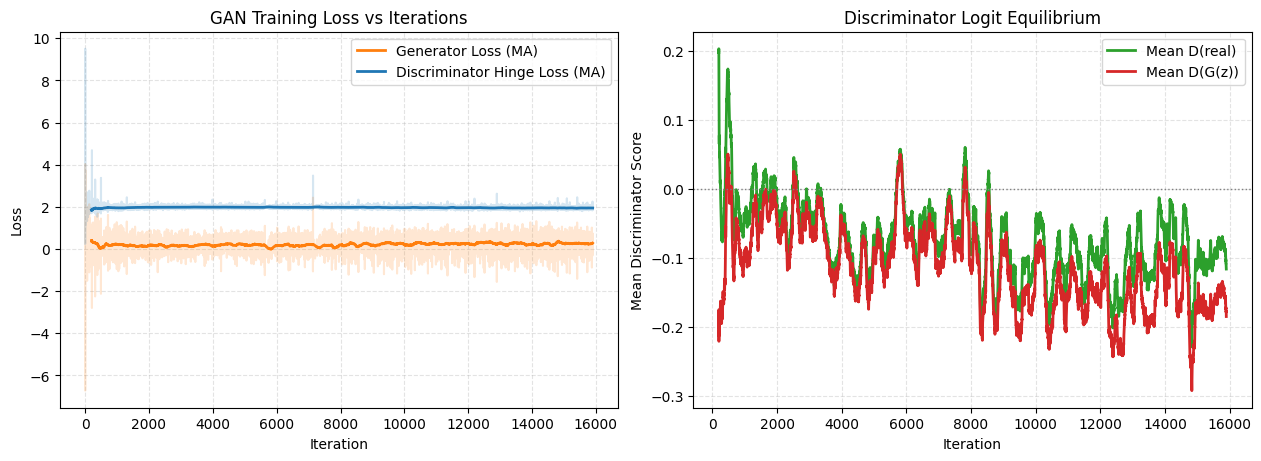

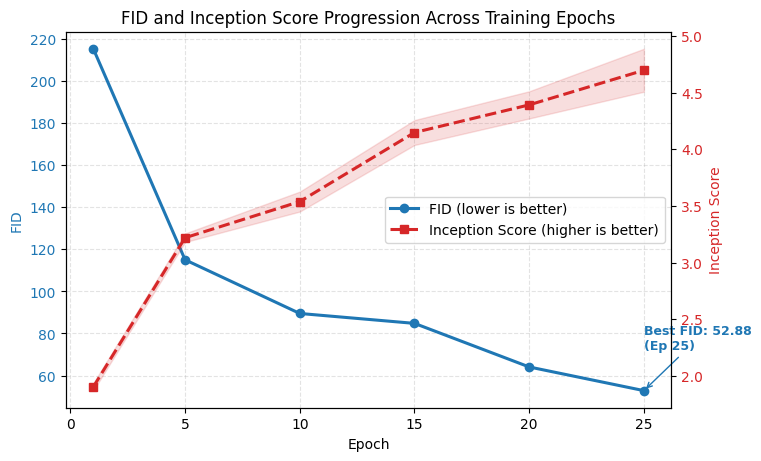

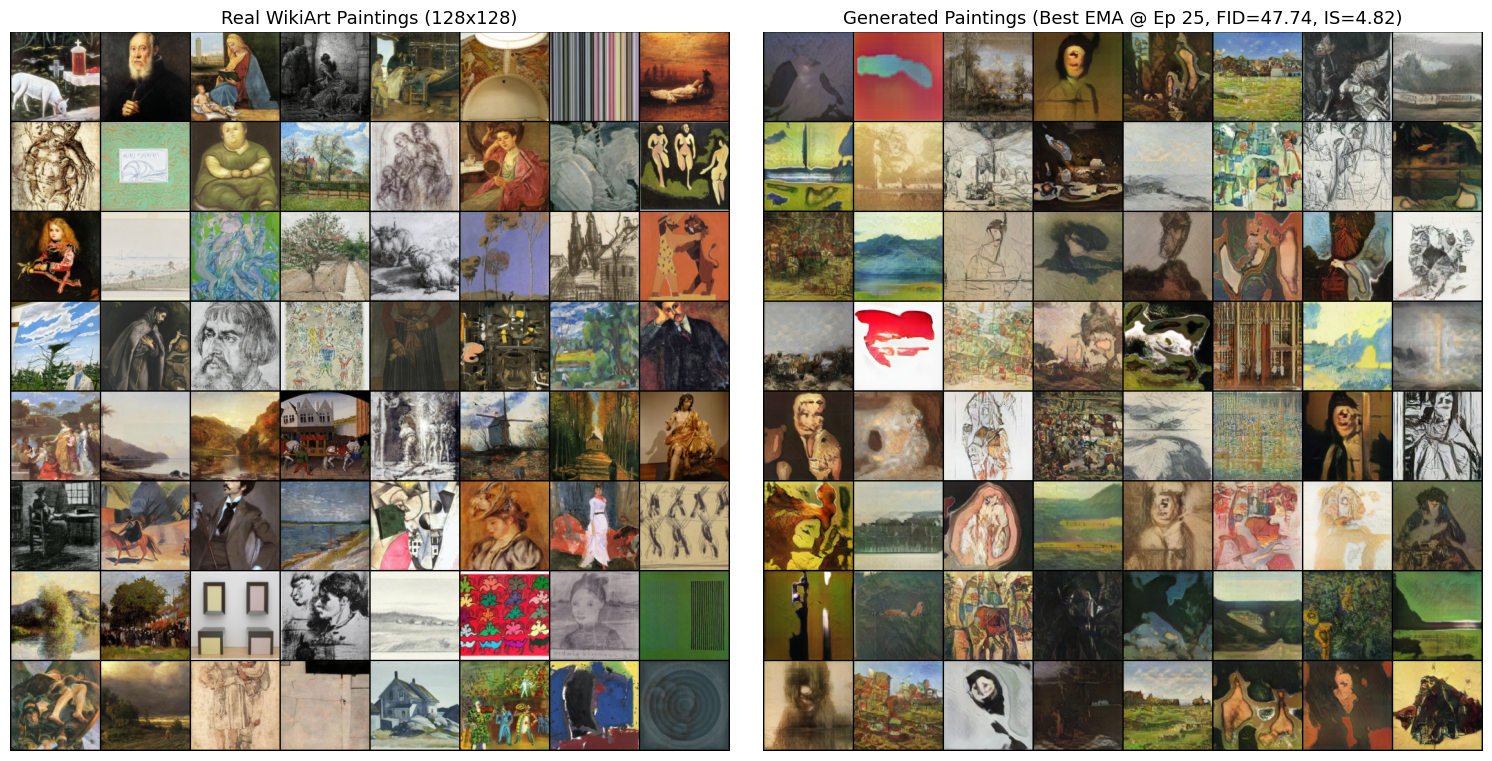

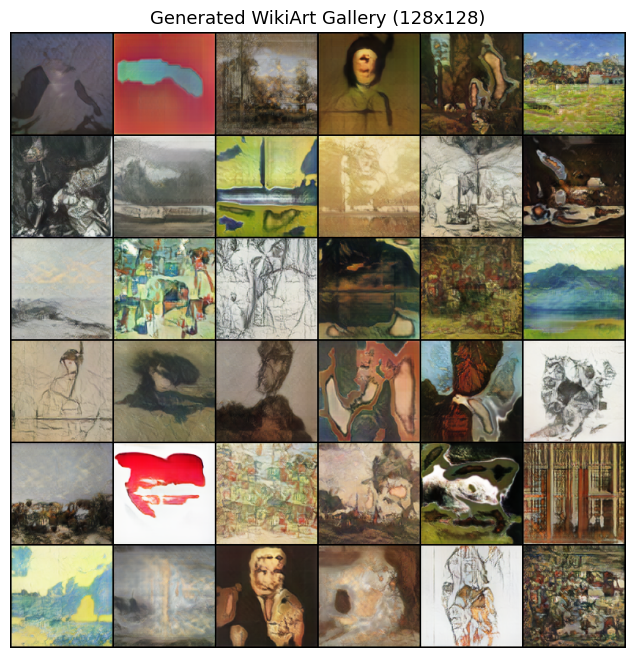

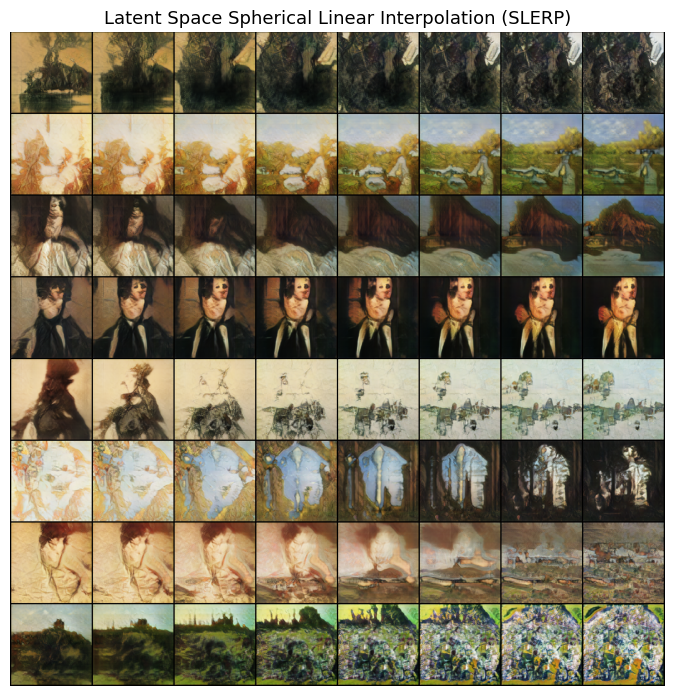

In [14]:
with open(history_path, "r", encoding="utf-8") as f:
    hist = json.load(f)

fig_dir = Path(CONFIG["output_dir"], "figures")

def moving_average(arr, window=100):
    if len(arr) < window:
        window = max(1, len(arr) // 5)
    if window <= 1:
        return np.asarray(arr)
    kernel = np.ones(window) / window
    return np.convolve(arr, kernel, mode="valid")

# --------------------------------------------------
# 图 1: Training Loss Curves & Discriminator Outputs
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)

g_raw = np.asarray(hist["iter_loss_G"])
d_raw = np.asarray(hist["iter_loss_D"])
w_ma = min(200, max(10, len(g_raw) // 30))
g_ma = moving_average(g_raw, w_ma)
d_ma = moving_average(d_raw, w_ma)

axes[0].plot(g_raw, color="tab:orange", alpha=0.18)
axes[0].plot(d_raw, color="tab:blue", alpha=0.18)
axes[0].plot(np.arange(len(g_ma)) + (len(g_raw) - len(g_ma)), g_ma, color="tab:orange", lw=2.0, label="Generator Loss (MA)")
axes[0].plot(np.arange(len(d_ma)) + (len(d_raw) - len(d_ma)), d_ma, color="tab:blue", lw=2.0, label="Discriminator Hinge Loss (MA)")
axes[0].set_title("GAN Training Loss vs Iterations")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle="--", alpha=0.35)
axes[0].legend()

dr_ma = moving_average(hist["iter_D_real"], w_ma)
df_ma = moving_average(hist["iter_D_fake"], w_ma)
axes[1].plot(np.arange(len(dr_ma)) + (len(g_raw) - len(dr_ma)), dr_ma, color="tab:green", lw=2.0, label="Mean D(real)")
axes[1].plot(np.arange(len(df_ma)) + (len(g_raw) - len(df_ma)), df_ma, color="tab:red", lw=2.0, label="Mean D(G(z))")
axes[1].axhline(0.0, color="gray", linestyle=":", lw=1.0)
axes[1].set_title("Discriminator Logit Equilibrium")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Mean Discriminator Score")
axes[1].grid(True, linestyle="--", alpha=0.35)
axes[1].legend()

fig.savefig(fig_dir / "loss_curves.png", dpi=300)
plt.show()

# --------------------------------------------------
# 图 2: FID & Inception Score Curves vs Epochs
# --------------------------------------------------
epochs_ev = np.asarray(hist["eval_epochs"])
fids = np.asarray(hist["fid_scores"])
is_m = np.asarray(hist["is_means"])
is_s = np.asarray(hist["is_stds"])

fig, ax1 = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
c_fid, c_is = "tab:blue", "tab:red"
l1 = ax1.plot(epochs_ev, fids, "o-", color=c_fid, lw=2.2, label="FID (lower is better)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("FID", color=c_fid)
ax1.tick_params(axis="y", labelcolor=c_fid)
ax1.grid(True, linestyle="--", alpha=0.35)

best_idx = int(np.argmin(fids))
ax1.annotate(
    f"Best FID: {fids[best_idx]:.2f}\n(Ep {epochs_ev[best_idx]})",
    xy=(epochs_ev[best_idx], fids[best_idx]),
    xytext=(epochs_ev[best_idx], fids[best_idx] + (fids.max() - fids.min()) * 0.12),
    arrowprops=dict(arrowstyle="->", color=c_fid),
    fontsize=9, color=c_fid, fontweight="bold"
)

ax2 = ax1.twinx()
l2 = ax2.plot(epochs_ev, is_m, "s--", color=c_is, lw=2.2, label="Inception Score (higher is better)")
ax2.fill_between(epochs_ev, is_m - is_s, is_m + is_s, color=c_is, alpha=0.15)
ax2.set_ylabel("Inception Score", color=c_is)
ax2.tick_params(axis="y", labelcolor=c_is)

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center right")
plt.title("FID and Inception Score Progression Across Training Epochs")
fig.savefig(fig_dir / "fid_is_curves.png", dpi=300)
plt.show()

# --------------------------------------------------
# 图 3: Real WikiArt vs Best EMA Generated Paintings
# --------------------------------------------------
best_ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
netG_ema.load_state_dict(best_ckpt["netG_ema"])
netG_ema.eval()

real_idx = dataset_meta["eval_indices"][:64]
real_64 = torch.from_numpy(np.ascontiguousarray(images_mm[real_idx])).permute(0, 3, 1, 2).float() / 255.0

with torch.no_grad():
    z_show = torch.randn(64, CONFIG["z_dim"], device=DEVICE)
    with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=CONFIG["use_amp"]):
        fake_64 = (netG_ema(z_show).float().clamp(-1.0, 1.0) + 1.0) * 0.5
    fake_64 = fake_64.cpu()

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True)
axes[0].axis("off")
axes[0].set_title(f"Real WikiArt Paintings ({IMG_SIZE}x{IMG_SIZE})", fontsize=13)
axes[0].imshow(vutils.make_grid(real_64, nrow=8, padding=2).permute(1, 2, 0).numpy())

summary_path = Path(CONFIG["output_dir"], "metrics_summary.json")
if summary_path.exists():
    with open(summary_path, "r", encoding="utf-8") as f:
        _sum = json.load(f)
    vis_fid, vis_is = _sum["final_fid"], _sum["final_is_mean"]
else:
    vis_fid, vis_is = float(best_ckpt["fid"]), float(best_ckpt["is_mean"])

axes[1].axis("off")
axes[1].set_title(f"Generated Paintings (Best EMA @ Ep {best_ckpt['epoch']}, FID={vis_fid:.2f}, IS={vis_is:.2f})", fontsize=13)
axes[1].imshow(vutils.make_grid(fake_64, nrow=8, padding=2).permute(1, 2, 0).numpy())

fig.savefig(fig_dir / "real_vs_fake.png", dpi=300)
plt.show()

# --------------------------------------------------
# 图 4: 精选 6x6 生成画廊
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))
ax.axis("off")
ax.set_title(f"Generated WikiArt Gallery ({IMG_SIZE}x{IMG_SIZE})", fontsize=13)
ax.imshow(vutils.make_grid(fake_64[:36], nrow=6, padding=2).permute(1, 2, 0).numpy())
fig.savefig(fig_dir / "generated_gallery.png", dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 图 5: 潜空间球面线性插值 (SLERP, 8x8)
# --------------------------------------------------
def slerp(val: float, low: torch.Tensor, high: torch.Tensor) -> torch.Tensor:
    low_n = low / torch.norm(low, dim=-1, keepdim=True).clamp_min(1e-8)
    high_n = high / torch.norm(high, dim=-1, keepdim=True).clamp_min(1e-8)
    omega = torch.acos(torch.clamp((low_n * high_n).sum(dim=-1, keepdim=True), -0.9999, 0.9999))
    so = torch.sin(omega)
    res = (torch.sin((1.0 - val) * omega) / so) * low + (torch.sin(val * omega) / so) * high
    return torch.where(so.abs() < 1e-6, (1.0 - val) * low + val * high, res)

with torch.no_grad():
    z_a = torch.randn(8, CONFIG["z_dim"], device=DEVICE)
    z_b = torch.randn(8, CONFIG["z_dim"], device=DEVICE)
    interp_zs = []
    for i in range(8):
        for alpha in np.linspace(0.0, 1.0, 8):
            interp_zs.append(slerp(float(alpha), z_a[i], z_b[i]))
    interp_z = torch.stack(interp_zs, dim=0)
    with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=CONFIG["use_amp"]):
        interp_imgs = (netG_ema(interp_z).float().clamp(-1.0, 1.0) + 1.0) * 0.5

fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.axis("off")
ax.set_title("Latent Space Spherical Linear Interpolation (SLERP)", fontsize=13)
ax.imshow(vutils.make_grid(interp_imgs.cpu(), nrow=8, padding=2).permute(1, 2, 0).numpy())
fig.savefig(fig_dir / "latent_interpolation.png", dpi=300, bbox_inches="tight")
plt.show()
